# Settings

In [122]:
file_path1 = "./data_nsi/csv/beamformed/005_sim_nsi_angle1_env_nsi.npy" 
file_path2 = "./data_nsi/csv/beamformed/005_sim_nsi_pos2_angle1_env_nsi.npy"

file_paths = [
    "./data_nsi/csv/beamformed/004_real_data_dc0_01_angle31_env_nsi.npy",
    "./data_nsi/csv/beamformed/006_real_nsi_31_angles_env_nsi.npy"
]


using_simulation_data = False

parameters_file_path = "./parameters_real_data.json"

visualizing_upsampled_data = True

# Imports

In [123]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [124]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [125]:
def calculate_variables_simulation(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    upsampled_step_size = step_size / interpolation_factor
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    params["simulation"]["upsampled_step_size"] = upsampled_step_size
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Upsampled step size: ", upsampled_step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [126]:
def calculate_variables_real_data(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    samples = params["wave"]["samples"]
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    upsampled_step_size = step_size / interpolation_factor

    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    params["simulation"]["upsampled_step_size"] = upsampled_step_size
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Upsampled step size: ", upsampled_step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [127]:
parameters = load_parameters(parameters_file_path)
if using_simulation_data:
    params, pos, time = calculate_variables_simulation(parameters)
else:
    params, pos, time = calculate_variables_real_data(parameters)

Aperture:  0.8
Samples:  834
Upsampled samples:  3333
Step size:  1.6e-08 s
Upsampled step size:  4e-09 s
Maximal acquisition depth: 0.010008000000000001 m
Lateral step:  2.25e-05 m


In [128]:
step_size = params["simulation"]["upsampled_step_size"] if visualizing_upsampled_data else params["simulation"]["step_size"]

# Import bf image data

(3333, 512)


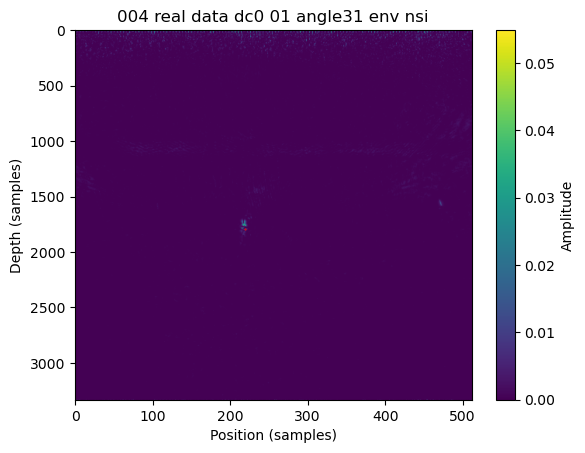

(3333, 512)


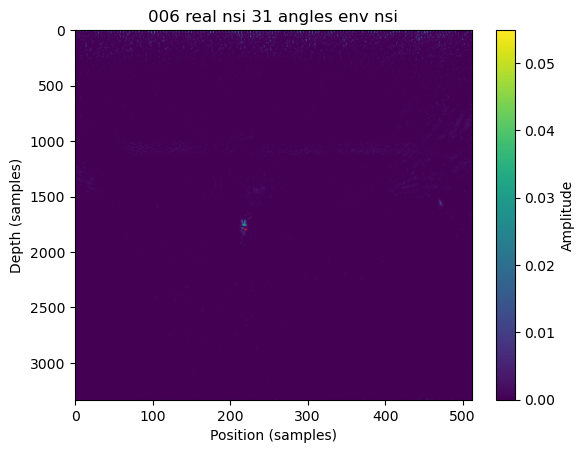

In [129]:
bf_matrices = np.zeros(
        (
        params["simulation"]["upsampled_samples"] if visualizing_upsampled_data else params["simulation"]["samples"], 
        params["simulation"]["lateral_resolution"], 
        len(file_paths)
        )
    )
labels = []

for idx, file_path in enumerate(file_paths):

    data = np.load(file_path)
    print(data.shape)

    max_row, max_col = np.unravel_index(np.argmax(np.abs(data)), data.shape)

    bf_matrices[:, :, idx] = data
    label = file_path.strip().split("/")[-1].split(".")[0].replace("_", " ")
    labels.append(label)

    plt.figure()
    plt.imshow(data, aspect='auto', cmap='viridis')
    plt.colorbar(label="Amplitude")
    plt.title(label)
    plt.xlabel("Position (samples)")
    plt.ylabel("Depth (samples)")
    plt.scatter(max_col, max_row, color='red', s=0.2)
    plt.show()

# Get high energy zone

In [130]:
def extract_highest_value_region_for_all(bf_matrices, depth_margin=15, lateral_margin=15):
    submatrices = []
    low_row_pos = np.inf
    high_row_pos = -np.inf
    low_col_pos = np.inf
    high_col_pos = -np.inf
    
    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        if row < low_row_pos:
            low_row_pos = row
        if row > high_row_pos:
            high_row_pos = row
        if col < low_col_pos:
            low_col_pos = col
        if col > high_col_pos:
            high_col_pos = col

    submatrices = bf_matrices[low_row_pos-depth_margin:high_row_pos+depth_margin, low_col_pos-lateral_margin:high_col_pos+lateral_margin, :]
    return submatrices

In [131]:
print(bf_matrices.shape)

(3333, 512, 2)


In [132]:
def extract_highest_value_region(bf_matrices, submatrix_size=100):
    submatrices = []

    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        half_size = int(submatrix_size/2)
        row_start = row - half_size if row - half_size >= 0 else 0
        row_end = row + half_size if row + half_size < bf_matrices.shape[0] else bf_matrices.shape[0]
        col_start = col - half_size if col - half_size >= 0 else 0
        col_end = col + half_size if col + half_size < bf_matrices.shape[1] else bf_matrices.shape[1]

        submatrices.append(bf_matrices[row_start:row_end, col_start:col_end, i])
        
    return submatrices

In [133]:
submatrices_standalone = extract_highest_value_region(bf_matrices, submatrix_size=120)

# Visualize lobes and resolution

In [134]:
def calculate_resolution(function):
    half_max = -6 #dB
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

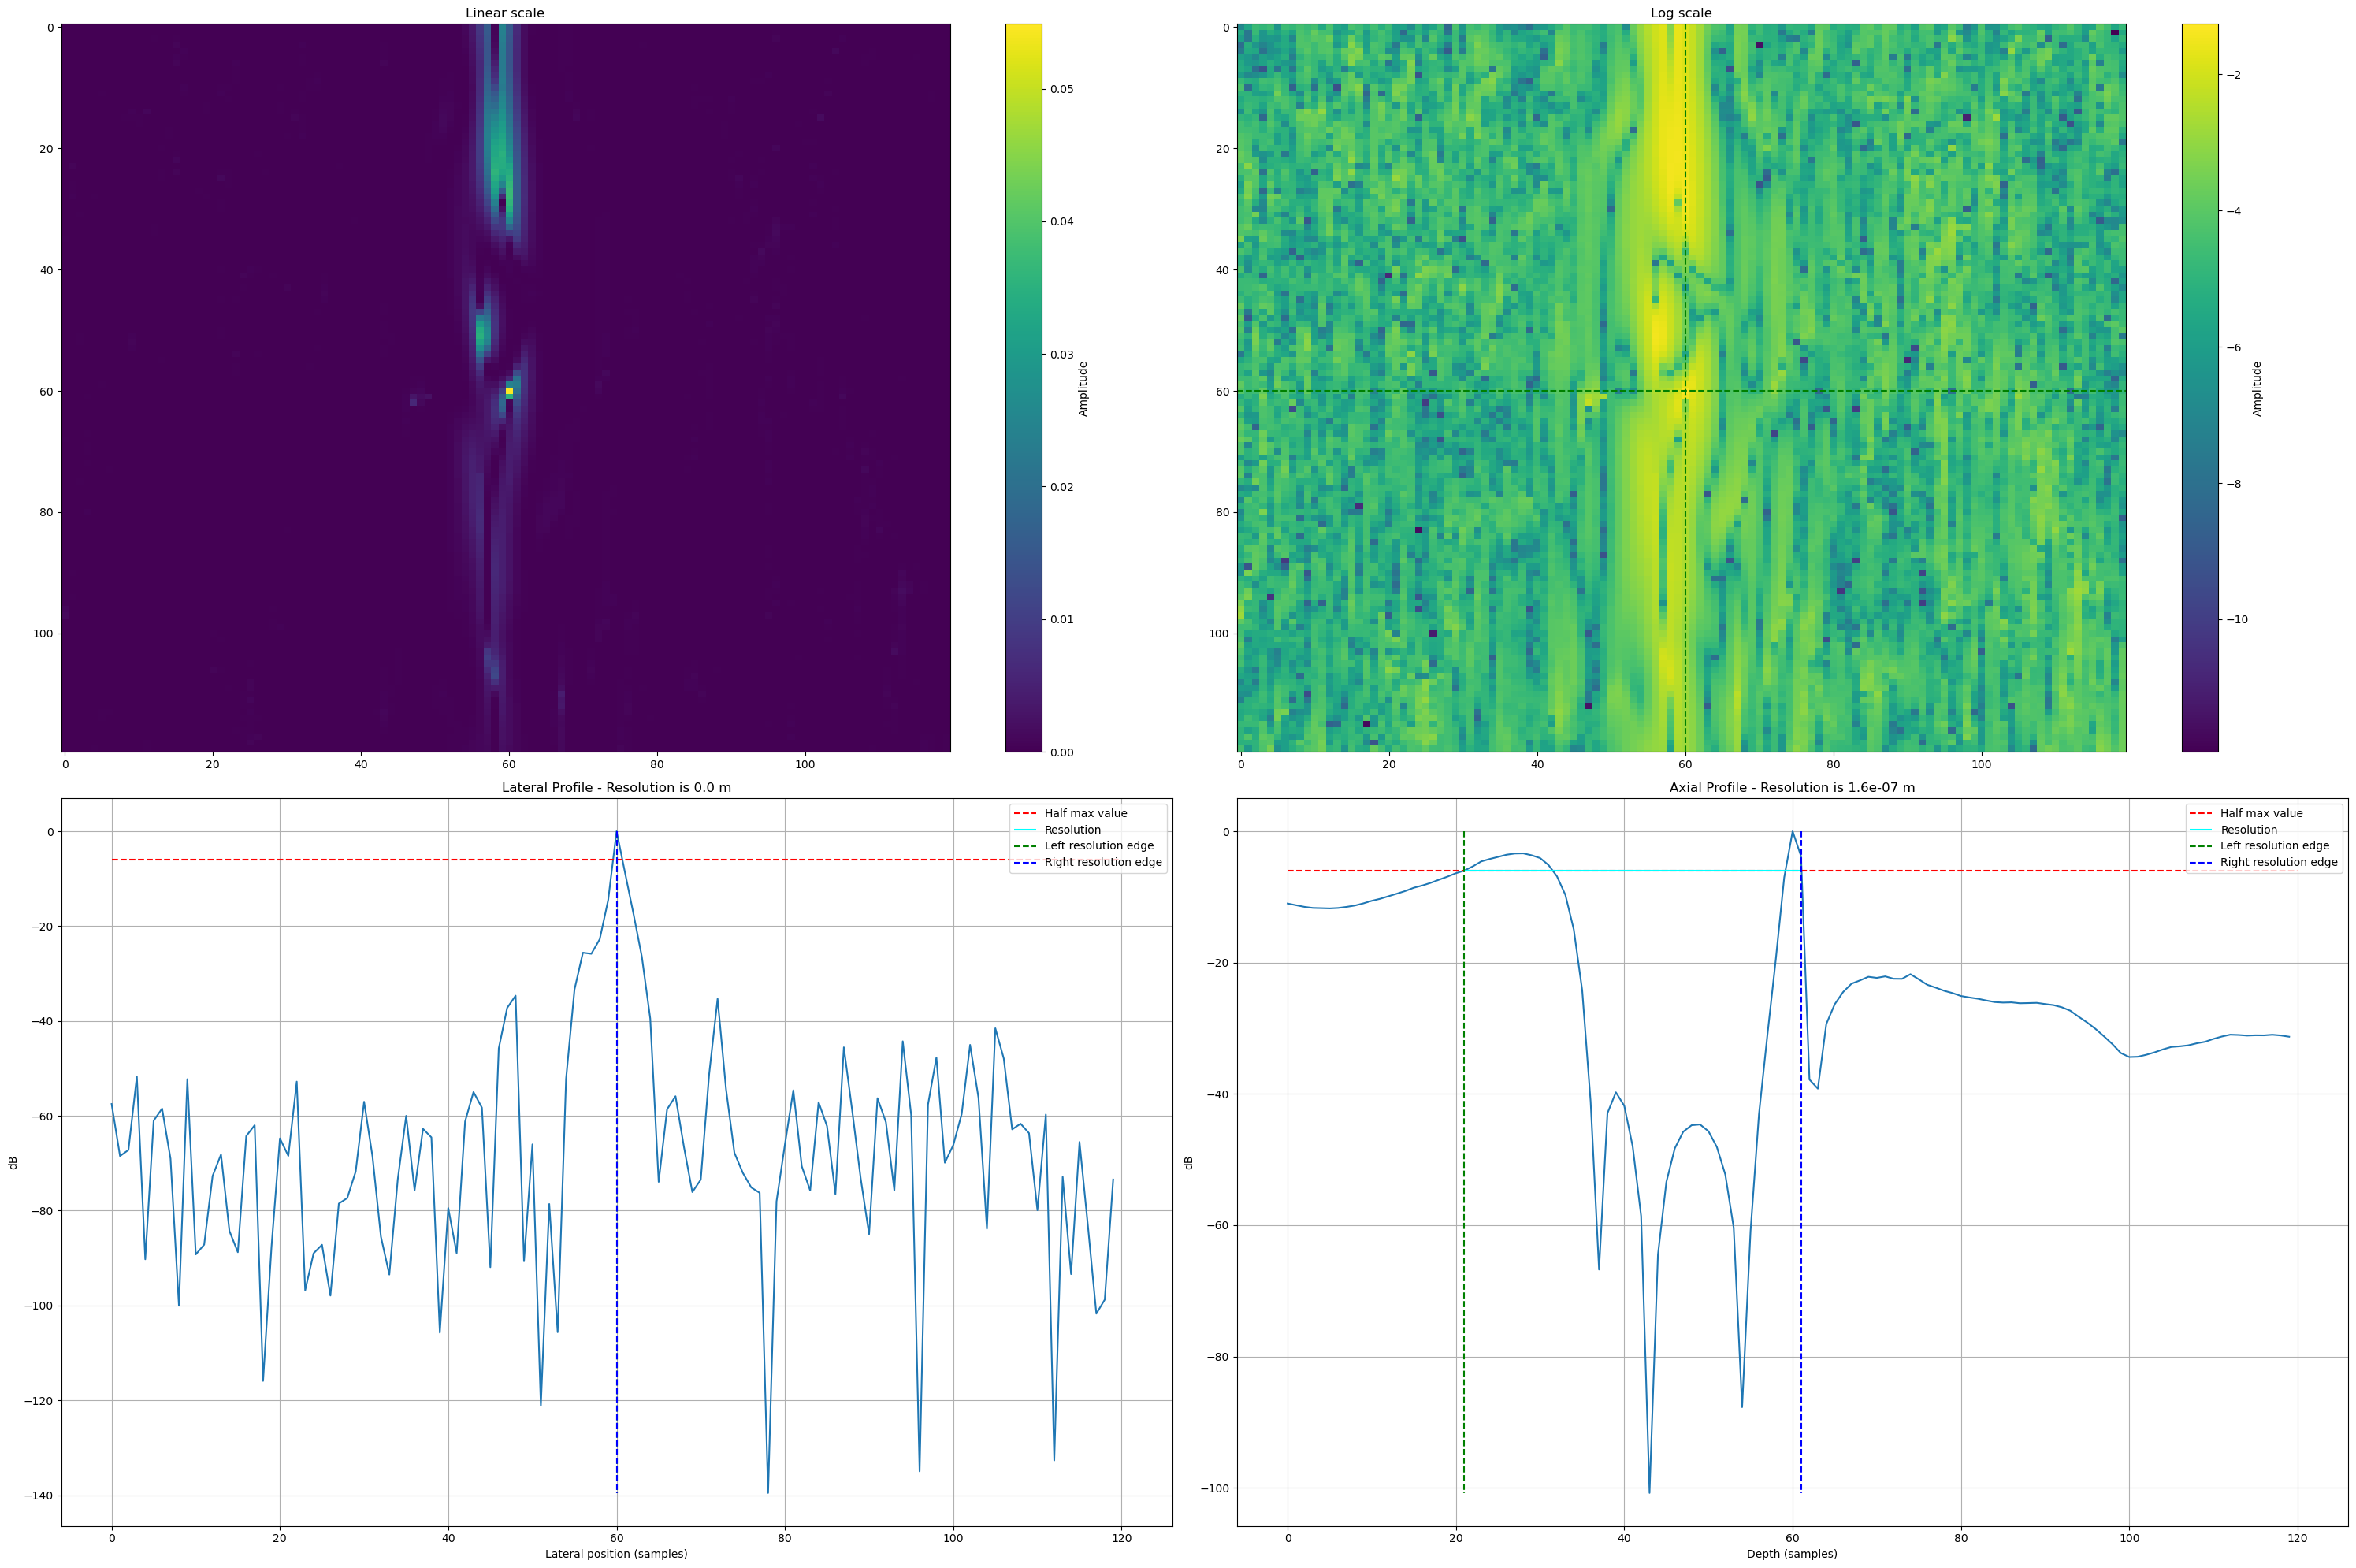

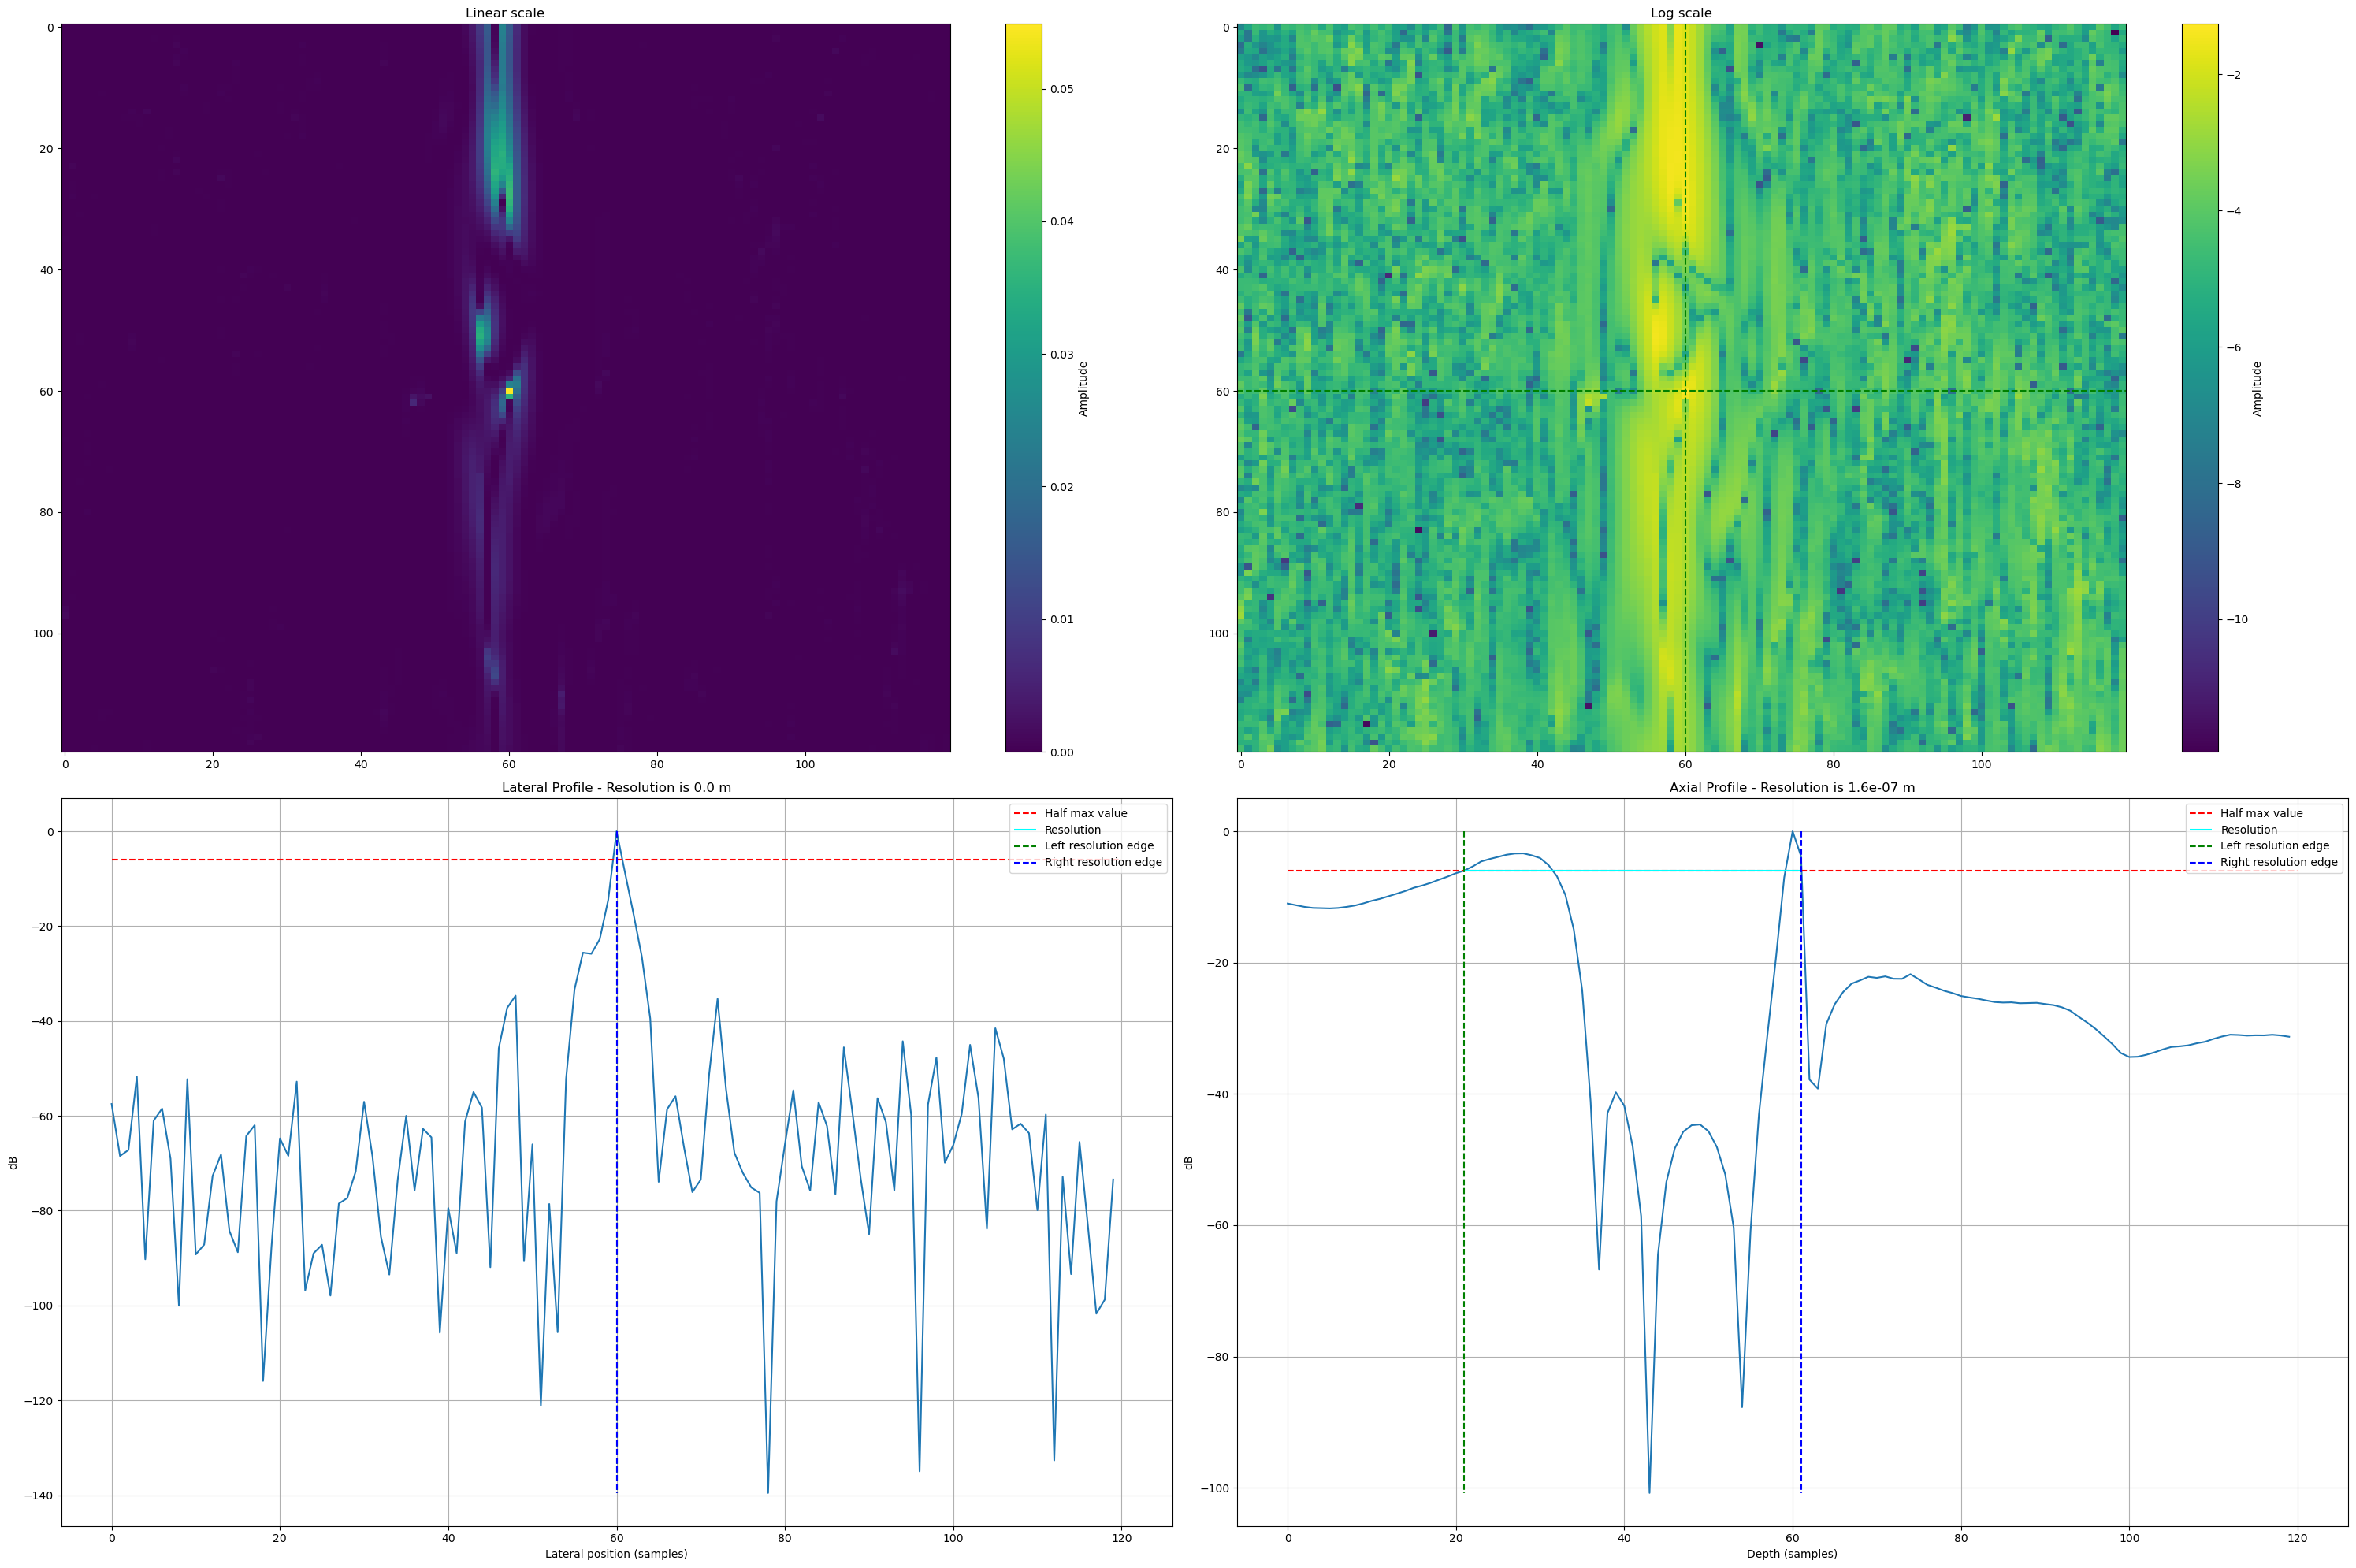

In [135]:
for idx, submatrix in enumerate(submatrices_standalone):
    
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix)), submatrix.shape) #max value position

    fig, ax = plt.subplots(2,2, figsize=(30, 20))

    # visulization of high energy zone
    im0 = ax[0,0].imshow(np.abs(submatrix), cmap='viridis', aspect='auto')
    ax[0,0].set_title("Linear scale")
    plt.colorbar(im0, label="Amplitude", ax=ax[0,0])

    #log view of high energy zone 
    im1 = ax[0,1].imshow(np.log10(np.abs(submatrix)), cmap='viridis', aspect='auto')
    ax[0,1].set_title("Log scale")
    ax[0,1].axhline(y=max_val_row, color='g', linestyle='--')
    ax[0,1].axvline(x=max_val_col, color='g', linestyle='--')
    plt.colorbar(im1, label="Amplitude", ax=ax[0,1])

    #visualization of lateral profile (Lateral res (horizontal))
    lateral_profile =  20 * np.log10(np.abs(submatrix[max_val_row, :]) / np.max(np.abs(submatrix[max_val_row, :]))) #we take values along the row with maximum value

    lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)

    im2 = ax[1,0].plot(lateral_profile)
    ax[1,0].set_title(f"Lateral Profile - Resolution is {lat_res * params['simulation']['lateral_step']} m")
    ax[1,0].set_xlabel("Lateral position (samples)")
    ax[1,0].set_ylabel("dB")
    ax[1,0].grid(True)
    ax[1,0].hlines(-6, 0, lateral_profile.shape[0], color='r', linestyle='--', label='Half max value')
    ax[1,0].hlines(-6, lat_left_idx, lat_right_idx, color='cyan', linestyle='-', label=f'Resolution')
    ax[1,0].vlines(lat_left_idx, 0, min(lateral_profile), color='g', linestyle='--', label='Left resolution edge')
    ax[1,0].vlines(lat_right_idx, 0, min(lateral_profile), color='b', linestyle='--', label='Right resolution edge')
    ax[1,0].legend()

    #visulization of axial resolution (vertical)
    axial_profile = 20 * np.log10(np.abs(submatrix[:, max_val_col]) / np.max(np.abs(submatrix[:, max_val_col]))) #we take values along the column with maximum value

    ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)

    im3 = ax[1,1].plot(axial_profile)
    ax[1,1].set_title(f"Axial Profile - Resolution is {ax_res * step_size} m")
    ax[1,1].set_xlabel("Depth (samples)")
    ax[1,1].set_ylabel("dB")
    ax[1,1].grid(True)
    ax[1,1].hlines(-6, 0, axial_profile.shape[0], color='r', linestyle='--', label='Half max value')
    ax[1,1].hlines(-6, ax_left_idx, ax_right_idx, color='cyan', linestyle='-', label=f'Resolution')
    ax[1,1].vlines(ax_left_idx, 0, min(axial_profile), color='g', linestyle='--', label='Left resolution edge')
    ax[1,1].vlines(ax_right_idx, 0, min(axial_profile), color='b', linestyle='--', label='Right resolution edge')
    ax[1,1].legend()

    plt.tight_layout()
    plt.show()

# Comparaison

In [136]:
def compare_resolutions(bf_matrices, step_size, lateral_step, labels, depth_margin=50, lateral_margin=15, ymin=None, ymax=None, xmin=None, xmax=None):
    submatrix = extract_highest_value_region_for_all(np.abs(bf_matrices), depth_margin= depth_margin, lateral_margin= lateral_margin)
    
    #viz
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].hlines(-6, 0, 0,colors='r', linestyles='--', label='Half max value (-6dB)')
    axes[1].hlines(-6, 0, 0, colors='r', linestyles='--', label='Half max value (-6dB)')


    for i in range(submatrix.shape[2]):
        
        max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)

        lateral_profile = 20 * np.log10(np.abs(submatrix[:,:,i][max_val_row, :]) / np.max(np.abs(submatrix[:,:,i][max_val_row, :])))
        axial_profile = 20 * np.log10(np.abs(submatrix[:,:,i][:, max_val_col]) / np.max(np.abs(submatrix[:,:,i][:, max_val_col])))

        #calculate resolutions
        lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)
        
        ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)
        
        #convert resolutions to meters
        lat_res_m = lat_res * lateral_step
        
        ax_res_m = ax_res * step_size
        
        #plot lateral profiles
        axes[0].plot(lateral_profile, label=f"{labels[i]} - {lat_res_m} m")
        axes[0].set_title("Lateral Profiles Comparison")
        axes[0].set_xlabel("Lateral position (samples)")
        axes[0].set_ylabel("Amplitude (dB)")
        axes[0].grid(True)
        axes[0].hlines(-6, 0, lateral_profile.shape[0], colors='r', linestyles='--')
        axes[0].set_ylim(ymin, ymax)
        axes[0].set_xlim(xmin, xmax)
        axes[0].legend()
        
        #plot axial profiles
        axes[1].plot(axial_profile, label=f"{labels[i]} - {ax_res_m} m")
        axes[1].set_title("Axial Profiles Comparison")
        axes[1].set_xlabel("Depth (samples)")
        axes[1].set_ylabel("Amplitude (dB)")
        axes[1].grid(True)
        axes[1].hlines(-6, 0, axial_profile.shape[0], colors='r', linestyles='--')
        axes[1].set_ylim(ymin, ymax)
        axes[1].legend()
        
    plt.tight_layout()
    plt.show()

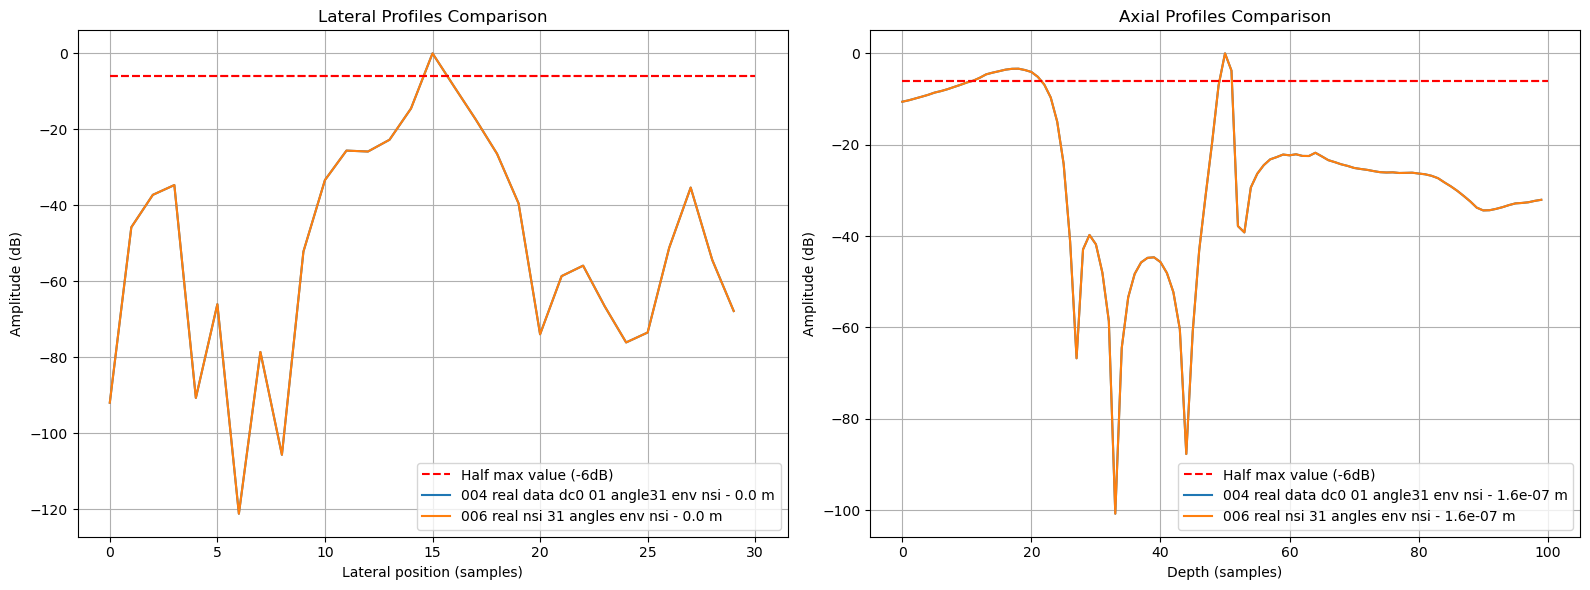

In [137]:
compare_resolutions(bf_matrices, step_size, params["simulation"]["lateral_step"], labels)